> ✅ **Versión resuelta** 

# 8 · Práctica integradora — Informe de Análisis Exploratorio (EDA)


> **¿Qué es esta práctica?**
> Es un **EDA completo**, de punta a punta, siguiendo los 5 pasos del flujo visto en la teoría:
> **01 Definir preguntas → 02 Conocer los datos → 03 Clasificar variables → 04 Evaluar la calidad → 05 Explorar y analizar**.
> Usa **solo** técnicas vistas en los notebooks 0 a 5. El resultado final es un **informe**: gráficos + conclusiones escritas.

> **Dataset nuevo (pero conocido):** usamos la versión **original** del *Breast Cancer Wisconsin (Diagnostic)*. Las variables son las mismas que en `sample_dataset.csv`, pero:
> - los nombres cambian de formato: `mean radius` → `radius_mean`, `radius error` → `radius_se`, `worst radius` → `radius_worst`;
> - el diagnóstico está en la columna **`diagnosis`** como texto: **`M` = maligno**, **`B` = benigno**;
> - hay una columna `id` (identificador de la muestra).

> **Si el notebook se reparte entre dos equipos:** Parte A = secciones 0 a 5 (calidad, univariado, outliers) · Parte B = secciones 6 a 9 (relaciones, correlación, informe). La Parte B igual ejecuta las celdas de las secciones 0 y 2 para cargar los datos.

**Cómo trabajar:** igual que en las guías: 📘 concepto · 💻 ejecutar · 🧩 completar `COMPLETAR` · ✍️ responder. En las secciones finales hay menos código armado: la idea es que **ustedes decidan** qué mirar.

## ✅ Checklist de entrega
- 1. Pregunta y fuente de datos
- 2. Exploración inicial y calidad de datos (faltantes, duplicados, columnas inútiles)
- 3. Clasificación de variables y balance de clases
- 4. Análisis univariado: descriptivos e histogramas (regla de Rice)
- 5. Boxplots, RIC y outliers + decisión fundamentada
- 6. Pairplot / jointplot con `hue`
- 7. Correlación (Pearson y Spearman) + heatmap
- 8. Informe final: 3 a 5 conclusiones con evidencia + limitaciones

## 0) Setup

In [31]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", None)   # mostrar todas las columnas al imprimir un DataFrame

## 1) Definir la pregunta y conocer la fuente (paso 01)

✍️ **Preguntas**
1. Escriban con sus palabras la **pregunta** que guía este análisis.
2. ¿Qué tipo de fuente es (primaria, secundaria o terciaria)? ¿Por qué importa saberlo?

✍️ **Respuesta del equipo:**

1. La pregunta es: ¿qué características de las células permiten diferenciar un tumor maligno de uno benigno?
2. Es una fuente secundaria, porque los datos los recolectó la Universidad de Wisconsin y nosotros los bajamos de un repositorio público. Importa porque no controlamos cómo se midieron, y eso puede afectar qué tan confiables son las conclusiones.

## 2) Carga, exploración inicial y calidad de datos (pasos 02 y 04 — notebooks 0 y 1)

In [32]:
#@title 💻 Cargar el dataset (ejecutar sin modificar)
url = "https://huggingface.co/datasets/scikit-learn/breast-cancer-wisconsin/raw/main/breast_cancer.csv"
try:
    df = pd.read_csv(url)
    print("Dataset cargado desde la URL.")
except Exception as e:
    # Plan B por si falla internet: armamos la misma tabla desde scikit-learn
    from sklearn.datasets import load_breast_cancer
    bc = load_breast_cancer(as_frame=True)
    datos = bc.frame.drop(columns="target")
    nuevos = {}
    for c in datos.columns:
        if c.startswith("mean "):
            nuevos[c] = c[5:].replace(" ", "_") + "_mean"
        elif c.startswith("worst "):
            nuevos[c] = c[6:].replace(" ", "_") + "_worst"
        else:
            nuevos[c] = c.replace(" error", "").replace(" ", "_") + "_se"
    df = datos.rename(columns=nuevos)
    df.insert(0, "diagnosis", bc.frame["target"].map({0: "M", 1: "B"}))
    df.insert(0, "id", range(1, len(df) + 1))
    print("No se pudo leer la URL; se cargó la versión de scikit-learn.")
df.head()

Dataset cargado desde la URL.


,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,fractal_dimension_mean,radius_se,texture_se,perimeter_se,area_se,smoothness_se,compactness_se,concavity_se,concave points_se,symmetry_se,fractal_dimension_se,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst,Unnamed: 32
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,1.0950,0.9053,8.589,153.40,0.006399,0.04904,0.05373,0.01587,0.03003,0.006193,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,NaN
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,0.5435,0.7339,3.398,74.08,0.005225,0.01308,0.01860,0.01340,0.01389,0.003532,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,NaN
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,0.7456,0.7869,4.585,94.03,0.006150,0.04006,0.03832,0.02058,0.02250,0.004571,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,NaN
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,0.4956,1.1560,3.445,27.23,0.009110,0.07458,0.05661,0.01867,0.05963,0.009208,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,NaN
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,0.7572,0.7813,5.438,94.44,0.011490,0.02461,0.05688,0.01885,0.01756,0.005115,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,NaN


🧩 Completen con lo visto en el notebook 0: **dimensiones** y **tipos de datos**.

In [33]:
print("Filas y columnas:", df.shape)     # pista: es un atributo, va sin paréntesis
df.dtypes                                    # tipos de dato de cada columna

Filas y columnas: (569, 33)


id                           int64
diagnosis                   object
radius_mean                float64
texture_mean               float64
perimeter_mean             float64
area_mean                  float64
smoothness_mean            float64
compactness_mean           float64
concavity_mean             float64
concave points_mean        float64
symmetry_mean              float64
fractal_dimension_mean     float64
radius_se                  float64
texture_se                 float64
perimeter_se               float64
area_se                    float64
smoothness_se              float64
compactness_se             float64
concavity_se               float64
concave points_se          float64
symmetry_se                float64
fractal_dimension_se       float64
radius_worst               float64
texture_worst              float64
perimeter_worst            float64
area_worst                 float64
smoothness_worst           float64
compactness_worst          float64
concavity_worst     

In [34]:
# Faltantes por columna (de mayor a menor) y filas duplicadas
print("Faltantes por columna:")
print(df.isna().sum().sort_values(ascending=False).head(5))
print("\nFilas duplicadas:", df.duplicated().sum())

# Columnas completamente vacías (pasa a veces con CSV exportados con una coma de más)
vacias = df.columns[df.isna().all()].tolist()
print("Columnas 100% vacías:", vacias)

Faltantes por columna:
Unnamed: 32     569
id                0
diagnosis         0
texture_mean      0
radius_mean       0
dtype: int64

Filas duplicadas: 0
Columnas 100% vacías: ['Unnamed: 32']


📘 **Columnas que no aportan al análisis.** El `id` es solo un identificador: no mide nada de la célula, así que no tiene sentido promediarlo, graficarlo ni correlacionarlo. Las columnas 100% vacías tampoco aportan. Las sacamos **documentando la decisión**.

In [35]:
df = df.drop(columns=["id"] + vacias)
df.shape

(569, 31)

✍️ **Diagnóstico de calidad de datos.** Comparen con `sample_dataset.csv` (notebooks 0 y 1):
1. ¿Hay faltantes? ¿Duplicados? ¿Tipos de dato incorrectos?
2. ¿Qué columnas eliminaron y por qué?

✍️ **Respuesta del equipo:**

1. No hay faltantes (salvo la columna `Unnamed: 32`, que está totalmente vacía), no hay duplicados y los tipos de dato están bien. Comparado con `sample_dataset.csv`, esta versión está limpia.
2. Sacamos `id` porque solo identifica la muestra y no mide nada de la célula, entonces no tiene sentido promediarlo ni correlacionarlo. También sacamos `Unnamed: 32` porque estaba vacía. Pasamos de 33 a 31 columnas.

## 3) Clasificar variables y balance de clases (paso 03)

diagnosis
B    357
M    212
Name: count, dtype: int64
diagnosis
B    0.627
M    0.373
Name: proportion, dtype: float64


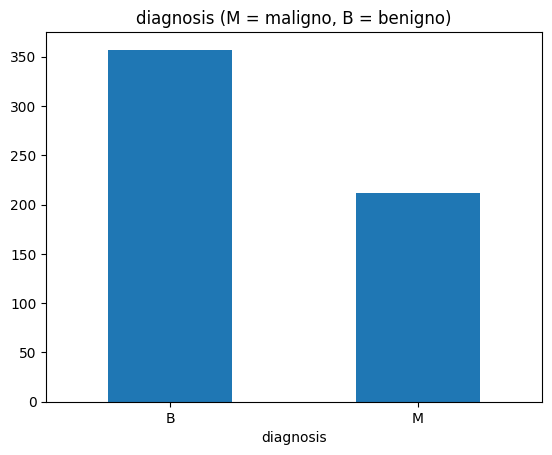

In [36]:
print(df["diagnosis"].value_counts())
print(df["diagnosis"].value_counts(normalize=True).round(3))

df["diagnosis"].value_counts().plot(kind="bar", title="diagnosis (M = maligno, B = benigno)", rot=0)
plt.show()

✍️ **Preguntas**
1. Clasifiquen `diagnosis` y `radius_mean` según la lámina *"Clasificación de variables"* (categórica nominal/ordinal, numérica discreta/continua).
2. ¿Las clases están balanceadas?

✍️ **Respuesta del equipo:**

1. `diagnosis` es categórica nominal (M o B, sin orden). `radius_mean` es numérica continua.
2. No están balanceadas del todo: 357 benignos (62,7%) y 212 malignos (37,3%). No es un desbalance gigante, pero hay que tenerlo presente al comparar.

## 4) Análisis univariado (paso 05 — notebooks 1 y 2)

💻 **Descriptivos.** Recuerden la lectura rápida del notebook 1: *count*, *media vs. mediana (50%)*, *max vs. 75%*, *escalas*.

In [37]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
radius_mean,569.0,14.127292,3.524049,6.981000,11.700000,13.370000,15.780000,28.11000
texture_mean,569.0,19.289649,4.301036,9.710000,16.170000,18.840000,21.800000,39.28000
perimeter_mean,569.0,91.969033,24.298981,43.790000,75.170000,86.240000,104.100000,188.50000
area_mean,569.0,654.889104,351.914129,143.500000,420.300000,551.100000,782.700000,2501.00000
smoothness_mean,569.0,0.096360,0.014064,0.052630,0.086370,0.095870,0.105300,0.16340
compactness_mean,569.0,0.104341,0.052813,0.019380,0.064920,0.092630,0.130400,0.34540
concavity_mean,569.0,0.088799,0.079720,0.000000,0.029560,0.061540,0.130700,0.42680
concave points_mean,569.0,0.048919,0.038803,0.000000,0.020310,0.033500,0.074000,0.20120
symmetry_mean,569.0,0.181162,0.027414,0.106000,0.161900,0.179200,0.195700,0.30400
fractal_dimension_mean,569.0,0.062798,0.007060,0.049960,0.057700,0.061540,0.066120,0.09744


✍️ **Preguntas**
1. ¿En qué variables la media es claramente mayor que la mediana? ¿Qué sugiere eso?
2. ¿Cuál es el orden de magnitud de `area_mean` vs. `smoothness_mean`? ¿Consideraría **estandarizar** en un futuro modelado?

✍️ **Respuesta del equipo:**

1. La media es claramente mayor que la mediana en `area_se` (40 contra 24), `concave points_mean`, `concavity_mean` y `area_worst`; en `area_mean` y `radius_mean` también, pero menos. Eso sugiere que tienen cola hacia la derecha, con valores altos que tiran la media.
2. `area_mean` está en los cientos (promedio 655) y `smoothness_mean` en 0,1 (promedio 0,096): son escalas muy distintas. Sí consideraríamos estandarizar si después se arma un modelo, para que las variables de escala grande no pesen más.

📘 **Histogramas con la regla de Rice:** $k = \lceil 2 \cdot n^{1/3} \rceil$

🧩 Completen la función y elijan **3 variables** para graficar (incluyan al menos `radius_mean` y `area_mean`).

Bins (Rice): 17


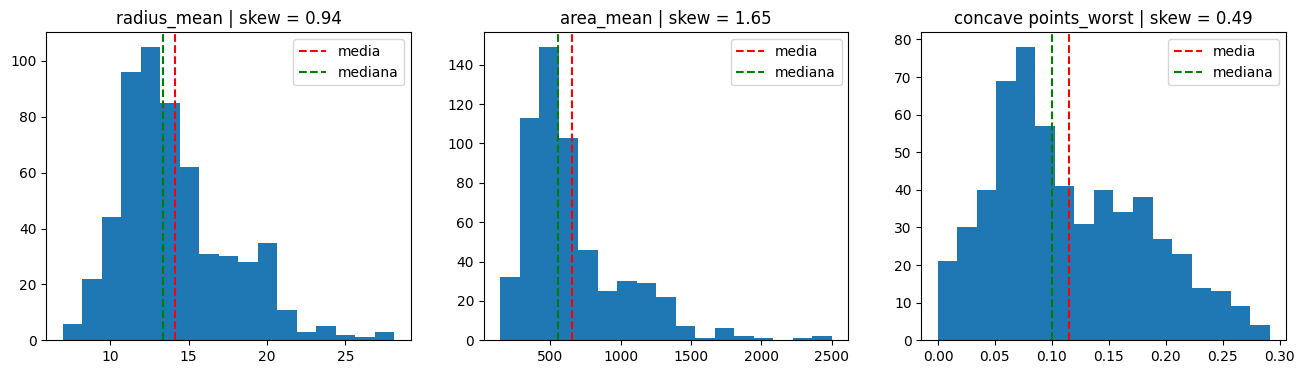

In [38]:
def rice_bins(n):
    return int(np.ceil(2 * n ** (1/3)))

bins = rice_bins(len(df))
print("Bins (Rice):", bins)

cols = ["radius_mean", "area_mean", "concave points_worst"]
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, c in zip(axes, cols):
    ax.hist(df[c].dropna(), bins=bins)
    ax.axvline(df[c].mean(), color="red", linestyle="--", label="media")
    ax.axvline(df[c].median(), color="green", linestyle="--", label="mediana")
    ax.set_title(f"{c} | skew = {df[c].skew():.2f}")
    ax.legend()
plt.show()

✍️ **Pregunta:** ¿Las distribuciones son simétricas o sesgadas? ¿Qué implicancia tiene para elegir entre media y mediana?

✍️ **Respuesta del equipo:**

Son asimétricas, con cola a la derecha: `radius_mean`, `area_mean` (la más marcada, con skew de 1,65) y `concave points_worst` (poco). En las tres la media es mayor que la mediana. Por eso, para describir el valor típico es mejor usar la mediana que la media.

## 5) Boxplots, RIC y outliers (paso 04/05 — notebook 3)

📘 Recordatorio: RIC = Q3 − Q1 · límites = Q1 − 1,5·RIC y Q3 + 1,5·RIC · outlier = valor fuera de esos límites.

In [39]:
def outlier_stats(s):
    s = s.dropna()
    q1, q3 = s.quantile(0.25), s.quantile(0.75)
    iqr = q3 - q1
    low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    mask = (s < low) | (s > high)
    return pd.Series({"Q1": q1, "Q3": q3, "RIC": iqr, "lim_inf": low, "lim_sup": high, "outliers": int(mask.sum())})

# Tabla resumen para las 3 variables elegidas en la sección 4
pd.DataFrame({c: outlier_stats(df[c]) for c in cols}).T.round(3)

,Q1,Q3,RIC,lim_inf,lim_sup,outliers
radius_mean,11.700,15.780,4.080,5.58,21.900,14.0
area_mean,420.300,782.700,362.400,-123.30,1326.300,25.0
concave points_worst,0.065,0.161,0.096,-0.08,0.306,0.0


🧩 Completen para hacer un **boxplot por diagnóstico** de cada variable (pista: la columna que separa los grupos).

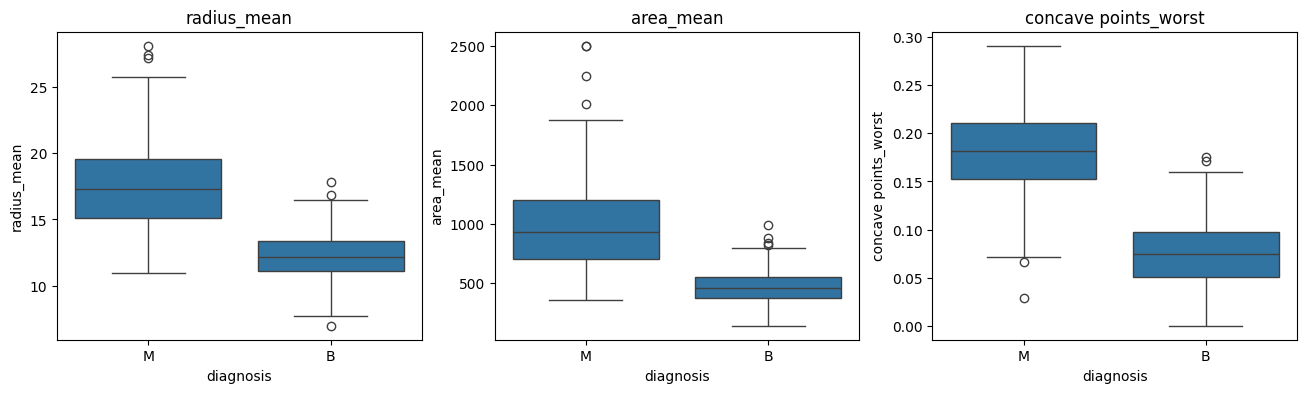

In [40]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, c in zip(axes, cols):
    sns.boxplot(data=df, x="diagnosis", y=c, ax=ax)
    ax.set_title(c)
plt.show()

✍️ **Pregunta:** ¿Cuántos outliers tiene cada variable y a qué diagnóstico corresponden? En este contexto exploratorio, ¿corresponde **eliminarlos** o **mantenerlos**? Justifiquen.

✍️ **Respuesta del equipo:**

`radius_mean` tiene 14 outliers y `area_mean` 25, y en los dos casos son todos malignos. `concave points_worst` no tiene ninguno. Pensamos que corresponde mantenerlos: no parecen errores sino tumores realmente grandes, y justo son los casos que más ayudan a diferenciar los diagnósticos. Si los eliminamos perderíamos a los malignos más claros. Lo que sí tenemos en cuenta es que pueden afectar a la media y a Pearson, por eso miramos también la mediana y Spearman.

## 6) Relaciones entre variables: pairplot y jointplot (notebook 4)

🧩 Elijan 4 o 5 variables (incluyan `radius_mean` y `area_mean`) y armen el pairplot con color por diagnóstico.

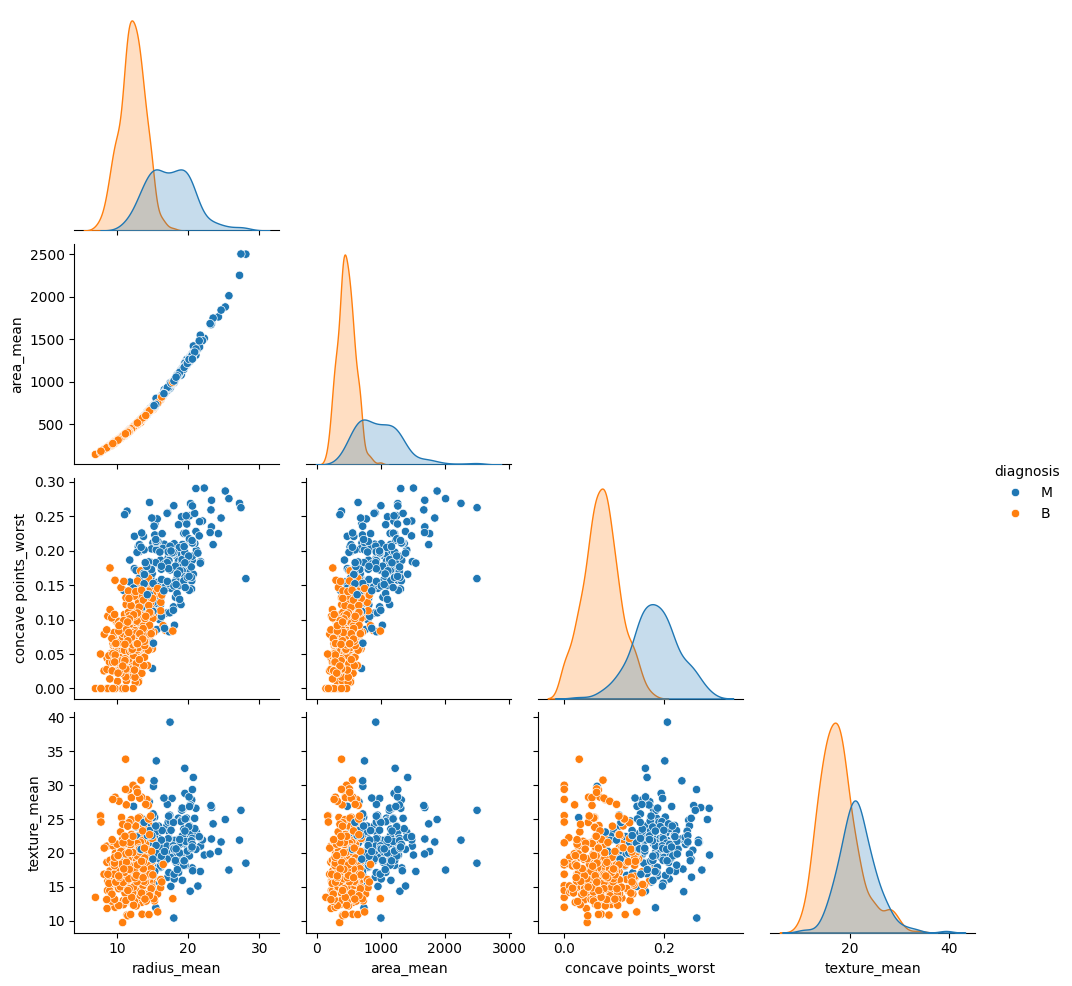

In [41]:
subset = ["radius_mean", "area_mean", "concave points_worst", "texture_mean"]
sns.pairplot(df, vars=subset, hue="diagnosis", corner=True)
plt.show()

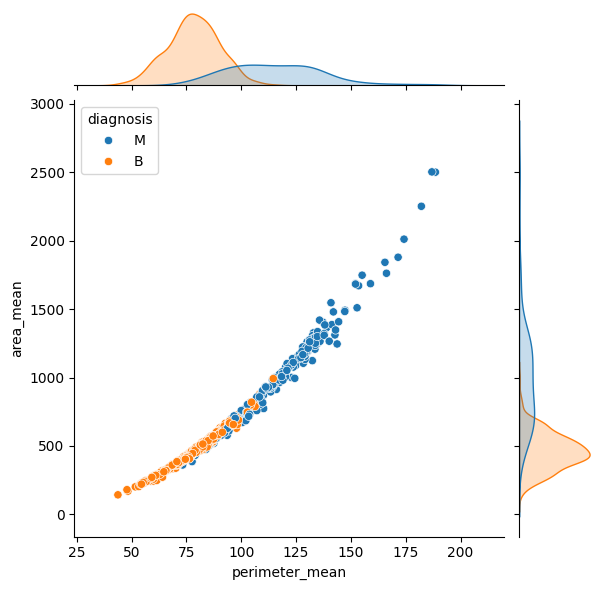

In [42]:
sns.jointplot(data=df, x="perimeter_mean", y="area_mean", hue="diagnosis")
plt.show()

✍️ **Pregunta:** Comenten **dos relaciones** interesantes (dirección, fuerza, si es lineal o curva) y qué variable separa mejor los diagnósticos.

✍️ **Respuesta del equipo:**

1. `radius_mean` y `area_mean`: relación positiva y muy fuerte, pero forma una curva y no una recta (el área crece con el radio al cuadrado). Los malignos quedan arriba a la derecha.
2. `radius_mean` y `concave points_worst`: relación positiva y fuerte, los núcleos más grandes tienen más puntos cóncavos.
Las variables que mejor separan los diagnósticos son `concave points_worst` y las de tamaño, como `radius_mean`. `texture_mean` se superpone bastante.

## 7) Correlación: Pearson vs. Spearman + heatmap (notebook 5)

📘 Para poder correlacionar el diagnóstico, lo pasamos a número. **Atención:** acá usamos **1 = maligno** (al revés que `target` en `sample_dataset.csv`), así que una correlación **positiva** indica asociación con **maligno**.

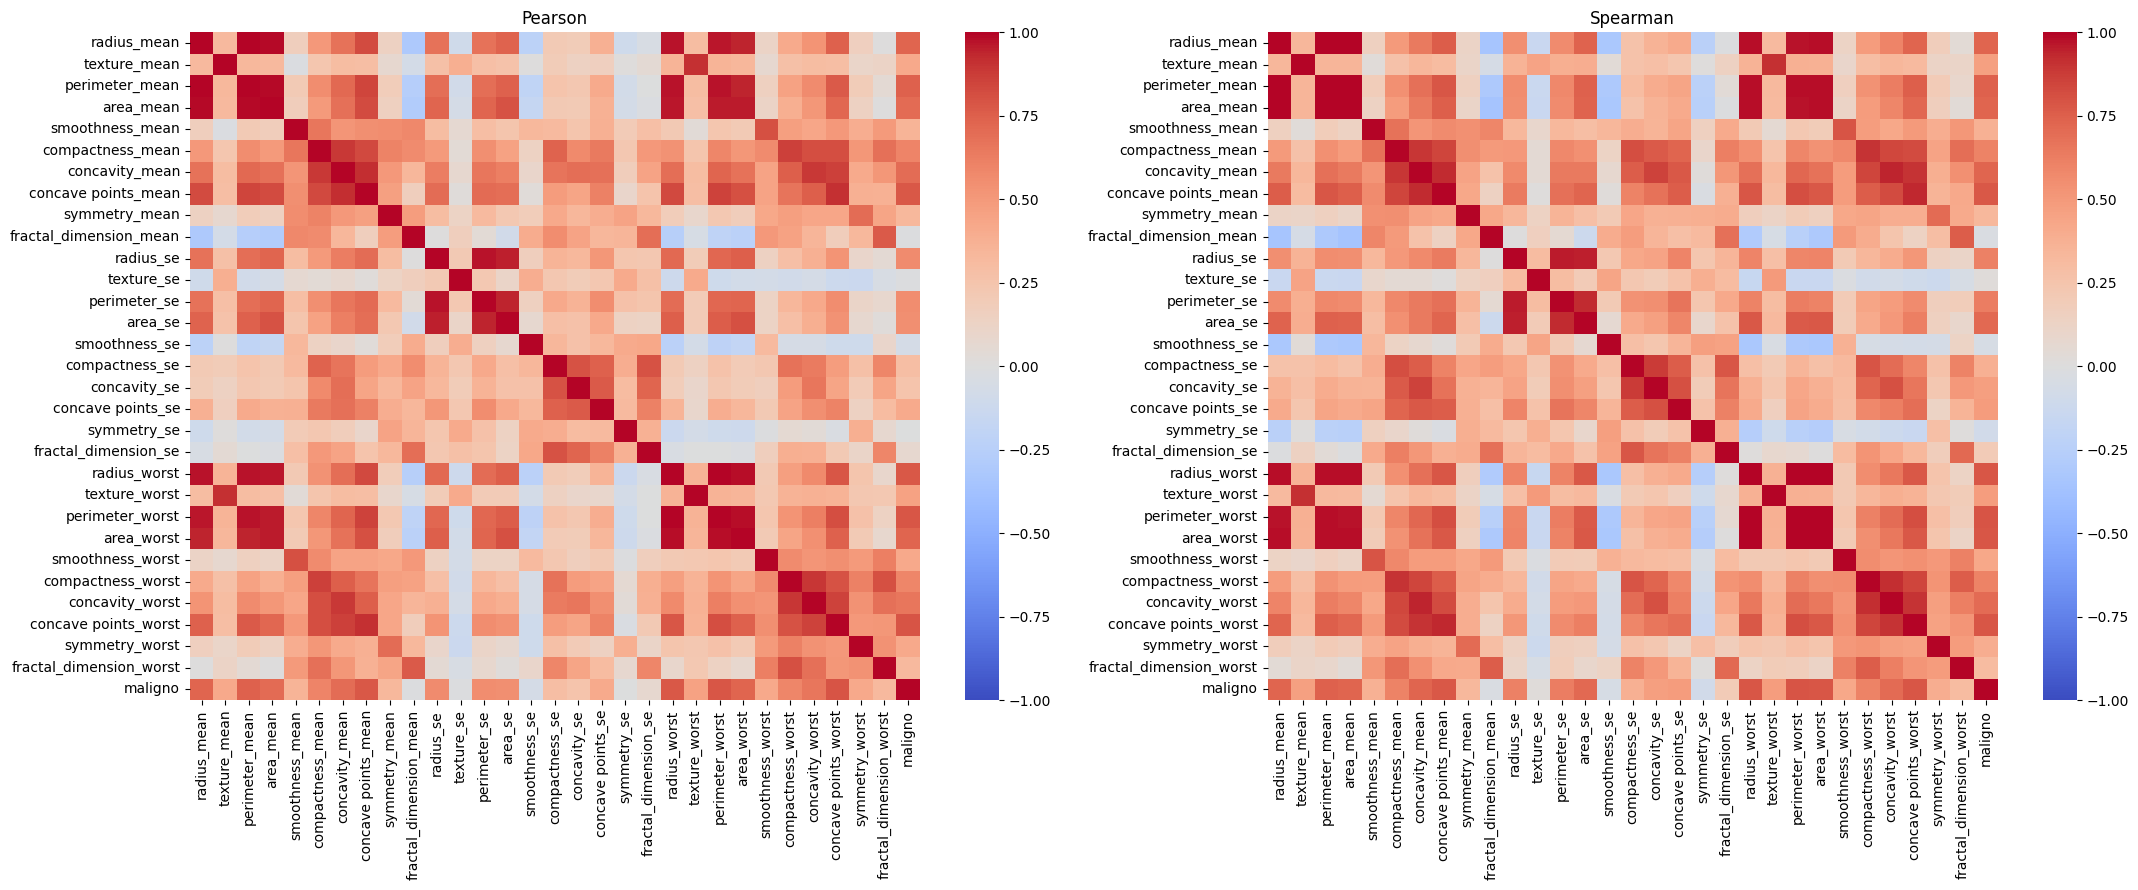

In [43]:
df["maligno"] = (df["diagnosis"] == "M").astype(int)   # 1 = maligno, 0 = benigno
num_df = df.select_dtypes(include="number")

corr_p = num_df.corr(method="pearson")
corr_s = num_df.corr(method="spearman")

fig, axes = plt.subplots(1, 2, figsize=(22, 9))
sns.heatmap(corr_p, cmap="coolwarm", vmin=-1, vmax=1, ax=axes[0]); axes[0].set_title("Pearson")
sns.heatmap(corr_s, cmap="coolwarm", vmin=-1, vmax=1, ax=axes[1]); axes[1].set_title("Spearman")
plt.tight_layout()
plt.show()

🧩 Ranking de variables más asociadas al diagnóstico con **los dos métodos**. Completen el nombre de la columna.

In [44]:
ranking = pd.DataFrame({
    "pearson": corr_p["maligno"],
    "spearman": corr_s["maligno"],
}).drop("maligno").sort_values("pearson", ascending=False)
ranking.head(10).round(2)

,pearson,spearman
concave points_worst,0.79,0.78
perimeter_worst,0.78,0.80
concave points_mean,0.78,0.78
radius_worst,0.78,0.79
perimeter_mean,0.74,0.75
area_worst,0.73,0.79
radius_mean,0.73,0.73
area_mean,0.71,0.73
concavity_mean,0.70,0.73
concavity_worst,0.66,0.71


✍️ **Preguntas**
1. Expliquen en 3–4 líneas **cuándo usar Pearson y cuándo Spearman**, y por qué en algunos pares cambia la magnitud.
2. ¿Qué variables son **redundantes** entre sí (correlación muy alta)? ¿Qué implicancia tiene?

✍️ **Respuesta del equipo:**

1. Pearson mide si la relación es lineal (una recta) y se afecta bastante por los outliers. Spearman mide si cuando una variable sube la otra sube siempre (o baja siempre), aunque sea en curva, y se afecta menos por los outliers porque trabaja con las posiciones (rangos) y no con los valores. Usaríamos Pearson si la relación parece una recta y no hay valores raros, y Spearman si hay curvas u outliers. En algunos pares cambia el valor, como `concavity_se` (0,25 con Pearson y 0,47 con Spearman) o `area_se`: son muy asimétricas y tienen outliers. En las más asociadas casi no cambia.
2. Son redundantes radius, perimeter y area (correlación alrededor de 0,99), y también concavity con concave points. Aportan casi la misma información, así que en un modelo nos quedaríamos con una de cada grupo.

## 8) 📝 Informe final

Completen la tabla con **entre 3 y 5 conclusiones**. Cada conclusión necesita **evidencia** (un gráfico o un número de este notebook).

| # | Hallazgo | Evidencia (gráfico / número) | ¿Qué implica? |
|---|---|---|---|
| 1 | | | |
| 2 | | | |
| 3 | | | |
| 4 | | | |
| 5 | | | |

**Variables más informativas para diferenciar diagnósticos:** ______

**Limitaciones de este análisis** (lámina *"Cómo interpretar los resultados de un EDA"*: causalidad, calidad de datos, alcance exploratorio, contexto): ______

✍️ **Respuesta del equipo:**

| # | Hallazgo | Evidencia | ¿Qué implica? |
|---|---|---|---|
| 1 | Los tumores malignos tienen núcleos más grandes | Mediana de `radius_mean`: 17,3 en malignos y 12,2 en benignos (boxplot por diagnóstico) | El tamaño ayuda a distinguir los diagnósticos |
| 2 | `concave points_worst` es de las variables más asociadas al diagnóstico | r = 0,79 con `maligno`; mediana 0,18 en malignos y 0,07 en benignos | Sería de las primeras a usar si se arma un modelo |
| 3 | Los outliers de tamaño son todos malignos | 14 en `radius_mean` y 25 en `area_mean`, todos M | Los mantenemos: son casos reales, no errores |
| 4 | Radio, perímetro y área son redundantes | Correlación de alrededor de 0,99 entre sí (pairplot y heatmap) | Dan casi la misma información: alcanza con una |
| 5 | El dataset está limpio pero las clases no están balanceadas, y `fractal_dimension_mean` no sirve para diferenciar | 0 faltantes y 0 duplicados; 62,7% benignos y 37,3% malignos; r = -0,01 con `maligno` | Hay que tener en cuenta el desbalance al comparar; esa variable no la priorizaríamos |

**Variables más informativas para diferenciar diagnósticos:** `concave points_worst`, `perimeter_worst`, `radius_worst` y `concave points_mean` (correlación de alrededor de 0,78 con Pearson y también con Spearman, así que no parece un efecto de los outliers).

**Limitaciones de este análisis:**
- No podemos hablar de causalidad: solo vimos asociaciones.
- Es un dataset de otra fuente (de 1995) y ya viene limpio, no sabemos bien cómo se midió.
- Es un análisis exploratorio: genera hipótesis, no las prueba.
- Nos falta conocimiento médico para interpretar qué significan las medidas.
- La correlación de Pearson con una variable de dos valores (maligno 0/1) es solo orientativa.

## 9) ⭐ (Opcional) Reporte automático (notebooks 6 y 7)

Las librerías **ydata-profiling** y **Sweetviz** generan en pocas líneas un informe con buena parte de lo que hicimos a mano. Úsenlo para **contrastar** sus conclusiones, no para reemplazarlas.

> Si Colab pide **reiniciar el entorno** después del `pip install`, reinicien y vuelvan a ejecutar desde el Setup.

In [45]:
#%pip install ydata-profiling
#%pip install ipywidgets

In [ ]:
from ydata_profiling import ProfileReport
reporte = ProfileReport(df[["diagnosis"] + cols], minimal=True)
reporte.to_notebook_iframe()

Render HTML: 100%|██████████| 1/1 [00:00<00:00, 17.48it/s]
